# TOI-4137 b Projected Obliquity Context

The example notebook builds `final_merged_df` from `ExoplanetsJumpstart/Resources/obliquity.csv` and merges it with the NASA Exoplanet Archive composite-parameters table. This notebook uses `ellc/run/data/population/obliquity.csv` instead: it has the same schema, but the copy in `ellc/run` has more rows and newer entries.

The obliquity catalog has repeated `errup`/`errdn` column names, so the data-loading cell below assigns explicit names for stellar-temperature, lambda, and psi uncertainties. The plotted y-errors are the projected-obliquity uncertainties.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_repo_root(start: Path) -> Path:
    """Find the repository root from either ellc/run or the repo root."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "ellc" / "run" / "data" / "population" / "obliquity.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find ellc/run/data/population/obliquity.csv")


REPO_ROOT = find_repo_root(Path.cwd())
RUN_DIR = REPO_ROOT / "ellc" / "run"
OBLIQUITY_CSV = RUN_DIR / "data" / "population" / "obliquity.csv"
PSCOMPARS_CSV = REPO_ROOT / "ExoplanetsJumpstart" / "Resources" / "PSCompPars_2025.09.18_09.20.11.csv"

STYLE = {
    "font_family": "sans-serif",
    "font_sans_serif": ["DejaVu Sans", "Arial", "Liberation Sans", "Helvetica"],
    "figure_size": (14, 6),
    "axes_labelsize": 24,
    "axes_titlesize": 24,
    "tick_labelsize": 18,
    "legend_fontsize": 17,
    "marker_size": 7,
    "toi_marker_size": 13,
    "line_width": 1.4,
    "cap_size": 3.5,
    "population_alpha": 0.5,
    "toi_alpha": 0.72,  # Diamond opacity; TOI-4137 b error bars remain opaque.
    "single_color": "tab:blue",
    "multi_color": "DarkRed",
    "toi_color": "black",
    "show_grid": False,  # Change to True to turn grid lines back on.
    "grid_alpha": 0.22,
    "grid_line_width": 0.8,
    "kraft_break_teff": 6250,
    "kraft_break_half_width": 150,  # +/- range in K; change this value to resize the boundary.
    "kraft_break_color": "0.25",
    "kraft_break_alpha": 0.16,
    "age_xlim": (-1, 15),
    "teff_xlim": None,
    "obliquity_ylim": (-300, 300),
}

plt.rcParams.update(
    {
        "font.family": STYLE["font_family"],
        "font.sans-serif": STYLE["font_sans_serif"],
        "mathtext.fontset": "dejavusans",
        "mathtext.default": "regular",
        "axes.labelsize": STYLE["axes_labelsize"],
        "axes.titlesize": STYLE["axes_titlesize"],
        "xtick.labelsize": STYLE["tick_labelsize"],
        "ytick.labelsize": STYLE["tick_labelsize"],
        "legend.fontsize": STYLE["legend_fontsize"],
        "figure.dpi": 130,
        "savefig.dpi": 300,
    }
)


In [3]:
OBLIQUITY_COLUMNS = [
    "System",
    "catalog_teff",
    "catalog_teff_errup",
    "catalog_teff_errdn",
    "Pflag",
    "lambda",
    "lambda_errup",
    "lambda_errdn",
    "psi",
    "psi_errup",
    "psi_errdn",
    "Author_string",
    "Ephemeris_reference",
]


def normalize_name(name: str) -> str:
    if pd.isna(name):
        return ""
    return (
        str(name)
        .strip()
        .lower()
        .replace("_", "")
        .replace("-0", "")
        .replace("-", "")
        .replace(" ", "")
    )


def numericize(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    for column in columns:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")
    return df


obliquity_raw = pd.read_csv(OBLIQUITY_CSV, skiprows=3, names=OBLIQUITY_COLUMNS)
obliquity_raw = numericize(
    obliquity_raw,
    [
        "catalog_teff",
        "catalog_teff_errup",
        "catalog_teff_errdn",
        "lambda",
        "lambda_errup",
        "lambda_errdn",
        "psi",
        "psi_errup",
        "psi_errdn",
    ],
)
obliquity_raw["Pflag"] = obliquity_raw["Pflag"].astype(str).str.strip()

pscomp_raw = pd.read_csv(PSCOMPARS_CSV, comment="#")
pscomp_raw = numericize(
    pscomp_raw,
    [
        "sy_pnum",
        "st_age",
        "st_ageerr1",
        "st_ageerr2",
        "st_teff",
        "st_tefferr1",
        "st_tefferr2",
    ],
)

obliquity = obliquity_raw.loc[
    (obliquity_raw["Pflag"] == "y") & (obliquity_raw["lambda"] > -900)
].copy()
pscomp = pscomp_raw.loc[pscomp_raw["discoverymethod"] == "Transit"].copy()

obliquity["system_key"] = obliquity["System"].map(normalize_name)
pscomp["planet_key"] = pscomp["pl_name"].map(normalize_name)
pscomp["host_key"] = pscomp["hostname"].map(normalize_name)

merged_by_planet = obliquity.merge(pscomp, left_on="system_key", right_on="planet_key", how="inner")
merged_by_planet["match_type"] = "planet name"
merged_by_host = obliquity.merge(pscomp, left_on="system_key", right_on="host_key", how="inner")
merged_by_host["match_type"] = "host name"

final_merged_df = pd.concat([merged_by_planet, merged_by_host], ignore_index=True)
final_merged_df["match_rank"] = final_merged_df["match_type"].map({"planet name": 0, "host name": 1})
final_merged_df = (
    final_merged_df.sort_values(["match_rank", "System", "pl_name"])
    .drop_duplicates(subset=["System", "lambda", "Author_string", "Ephemeris_reference"], keep="first")
    .reset_index(drop=True)
)

matched_systems = set(final_merged_df["System"])
unmatched_obliquities = obliquity.loc[~obliquity["System"].isin(matched_systems)].copy()

final_merged_df["plot_teff"] = final_merged_df["st_teff"].fillna(final_merged_df["catalog_teff"])
final_merged_df["plot_tefferr1"] = final_merged_df["st_tefferr1"].fillna(final_merged_df["catalog_teff_errup"])
final_merged_df["plot_tefferr2"] = final_merged_df["st_tefferr2"].fillna(-final_merged_df["catalog_teff_errdn"])

TOI_NAME = "TOI-4137 b"
toi_archive_matches = pscomp_raw.loc[pscomp_raw["pl_name"].astype(str).str.strip() == TOI_NAME]
if toi_archive_matches.empty:
    raise ValueError(f"Could not find {TOI_NAME} in {PSCOMPARS_CSV}")

toi_archive = toi_archive_matches.iloc[0]
toi_4137b = pd.Series(
    {
        "pl_name": TOI_NAME,
        "hostname": toi_archive["hostname"],
        "sy_pnum": toi_archive["sy_pnum"],
        "lambda": 13.2,
        "lambda_errup": 4.6,
        "lambda_errdn": 4.5,
        "st_age": toi_archive["st_age"],
        "st_ageerr1": toi_archive["st_ageerr1"],
        "st_ageerr2": toi_archive["st_ageerr2"],
        "plot_teff": 6134.0,
        "plot_tefferr1": 50.0,
        "plot_tefferr2": -50.0,
        "archive_st_teff": toi_archive["st_teff"],
        "archive_st_tefferr1": toi_archive["st_tefferr1"],
        "archive_st_tefferr2": toi_archive["st_tefferr2"],
    }
)

print(f"Using obliquity catalog: {OBLIQUITY_CSV}")
print(f"Using composite-parameters table: {PSCOMPARS_CSV}")
print(f"Preferred projected-obliquity measurements with lambda values: {len(obliquity)}")
print(f"Merged population measurements available for plotting: {len(final_merged_df)}")
print(f"Unmatched preferred measurements: {len(unmatched_obliquities)}")
print(
    "TOI-4137 b age from PSCompPars: "
    f"{toi_4137b['st_age']:.2f} +{toi_4137b['st_ageerr1']:.2f} "
    f"/{toi_4137b['st_ageerr2']:.2f} Gyr"
)
print(
    "TOI-4137 b Teff used for plotting: "
    f"{toi_4137b['plot_teff']:.0f} +/- {toi_4137b['plot_tefferr1']:.0f} K "
    f"(PSCompPars lists {toi_4137b['archive_st_teff']:.0f} K)"
)


Using obliquity catalog: /home/eraul/wisconsin/work/exoplanets_dynamics_research_2025/ellc/run/data/population/obliquity.csv
Using composite-parameters table: /home/eraul/wisconsin/work/exoplanets_dynamics_research_2025/ExoplanetsJumpstart/Resources/PSCompPars_2025.09.18_09.20.11.csv
Preferred projected-obliquity measurements with lambda values: 314
Merged population measurements available for plotting: 252
Unmatched preferred measurements: 62
TOI-4137 b age from PSCompPars: 2.10 +1.30 /-1.00 Gyr
TOI-4137 b Teff used for plotting: 6134 +/- 50 K (PSCompPars lists 6202 K)


In [4]:
def asym_err(lower, upper):
    lower = pd.to_numeric(lower, errors="coerce").abs().to_numpy(dtype=float)
    upper = pd.to_numeric(upper, errors="coerce").abs().to_numpy(dtype=float)
    return np.vstack([lower, upper])


def scalar_asym_err(lower, upper):
    return np.array([[abs(float(lower))], [abs(float(upper))]])


def plot_population_group(ax, df, x_col, xerr_lower_col, xerr_upper_col, marker, color, label):
    if df.empty:
        return
    ax.errorbar(
        df[x_col],
        df["lambda"],
        xerr=asym_err(df[xerr_lower_col], df[xerr_upper_col]),
        yerr=asym_err(df["lambda_errdn"], df["lambda_errup"]),
        fmt=marker,
        linestyle="None",
        markersize=STYLE["marker_size"],
        markeredgewidth=0.8,
        color=color,
        ecolor=color,
        elinewidth=STYLE["line_width"],
        capsize=STYLE["cap_size"],
        alpha=STYLE["population_alpha"],
        label=label,
        zorder=2,
    )


def plot_toi_4137b(ax, x, xerr_lower, xerr_upper):
    ax.errorbar(
        [x],
        [toi_4137b["lambda"]],
        xerr=scalar_asym_err(xerr_lower, xerr_upper),
        yerr=scalar_asym_err(toi_4137b["lambda_errdn"], toi_4137b["lambda_errup"]),
        fmt="none",
        linestyle="None",
        color=STYLE["toi_color"],
        ecolor=STYLE["toi_color"],
        elinewidth=STYLE["line_width"] + 0.8,
        capsize=STYLE["cap_size"] + 1.5,
        alpha=1.0,
        zorder=9,
    )
    ax.plot(
        [x],
        [toi_4137b["lambda"]],
        marker="D",
        linestyle="None",
        markersize=STYLE["toi_marker_size"],
        markerfacecolor=STYLE["toi_color"],
        markeredgecolor=STYLE["toi_color"],
        markeredgewidth=0.8,
        alpha=STYLE["toi_alpha"],
        label="TOI-4137 b",
        zorder=10,
    )


def format_obliquity_axis(ax, xlabel):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"Projected obliquity (deg)")
    ax.set_ylim(*STYLE["obliquity_ylim"])
    ax.tick_params(axis="both", which="major", labelsize=STYLE["tick_labelsize"])
    ax.grid(STYLE["show_grid"], alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=STYLE["legend_fontsize"])


def single_multi_split(df):
    single = df.loc[df["sy_pnum"] <= 1].copy()
    multi = df.loc[df["sy_pnum"] > 1].copy()
    return single, multi


/tmp/ipykernel_625436/2799617811.py:60: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(STYLE["show_grid"], alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])


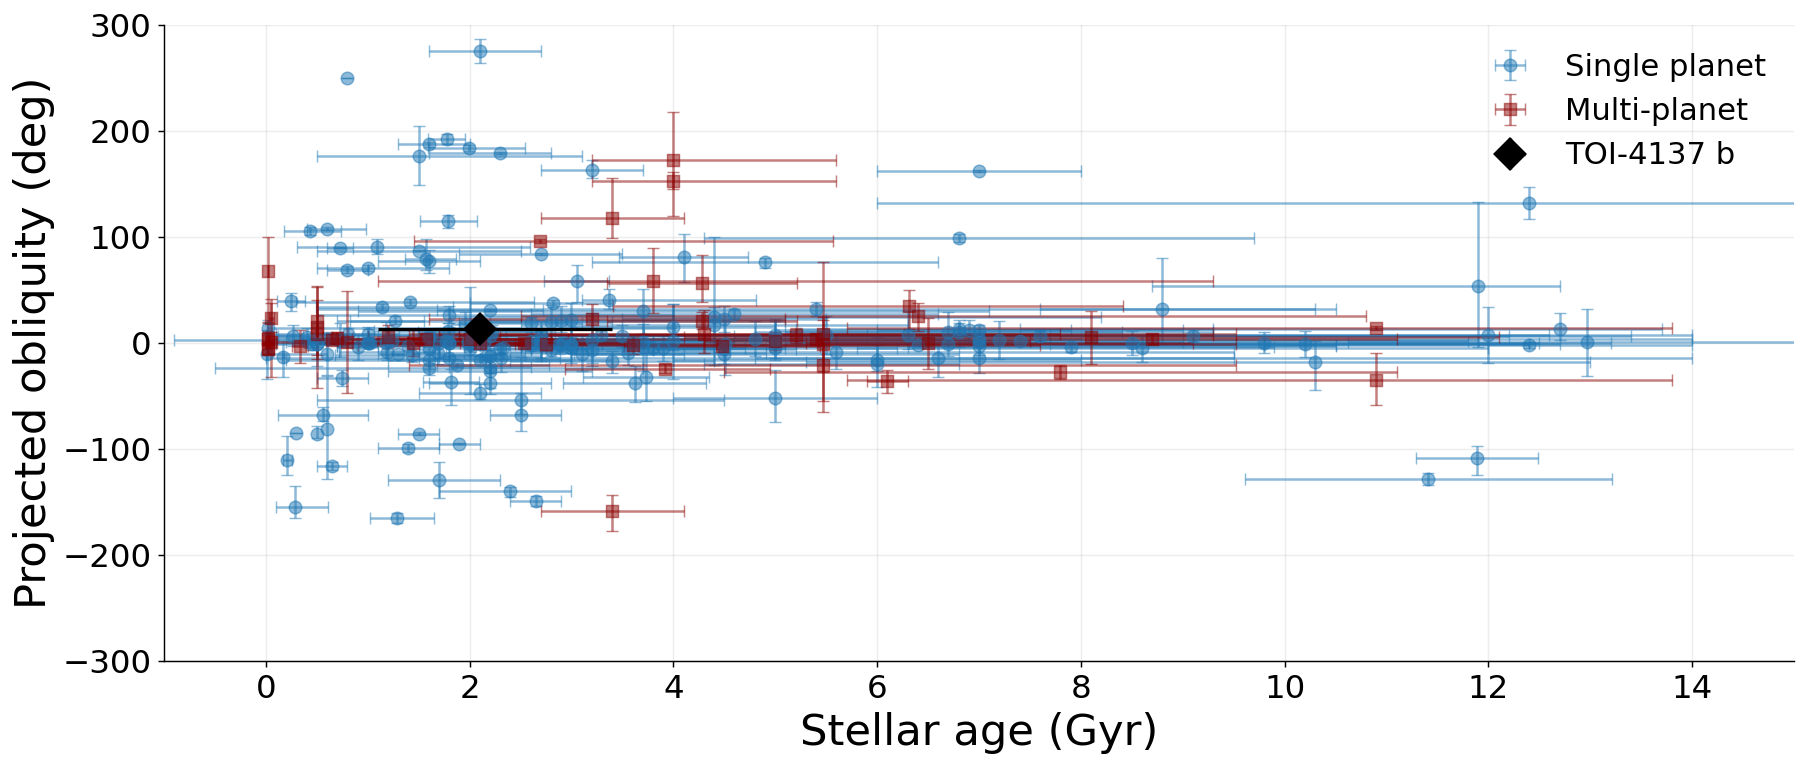

In [5]:
age_df = final_merged_df.loc[
    final_merged_df["lambda"].notna() & final_merged_df["st_age"].notna()
].copy()
single_age_df, multi_age_df = single_multi_split(age_df)

fig, ax = plt.subplots(figsize=STYLE["figure_size"])
plot_population_group(
    ax,
    single_age_df,
    x_col="st_age",
    xerr_lower_col="st_ageerr2",
    xerr_upper_col="st_ageerr1",
    marker="o",
    color=STYLE["single_color"],
    label="Single planet",
)
plot_population_group(
    ax,
    multi_age_df,
    x_col="st_age",
    xerr_lower_col="st_ageerr2",
    xerr_upper_col="st_ageerr1",
    marker="s",
    color=STYLE["multi_color"],
    label="Multi-planet",
)
plot_toi_4137b(
    ax,
    x=toi_4137b["st_age"],
    xerr_lower=toi_4137b["st_ageerr2"],
    xerr_upper=toi_4137b["st_ageerr1"],
)

ax.set_xlim(*STYLE["age_xlim"])
format_obliquity_axis(ax, r"Stellar age (Gyr)")
plt.tight_layout()
plt.show()


## Real Paper Plot

Saved figure to: /home/eraul/wisconsin/work/exoplanets_dynamics_research_2025/ellc/run/plots/population_plot.pdf


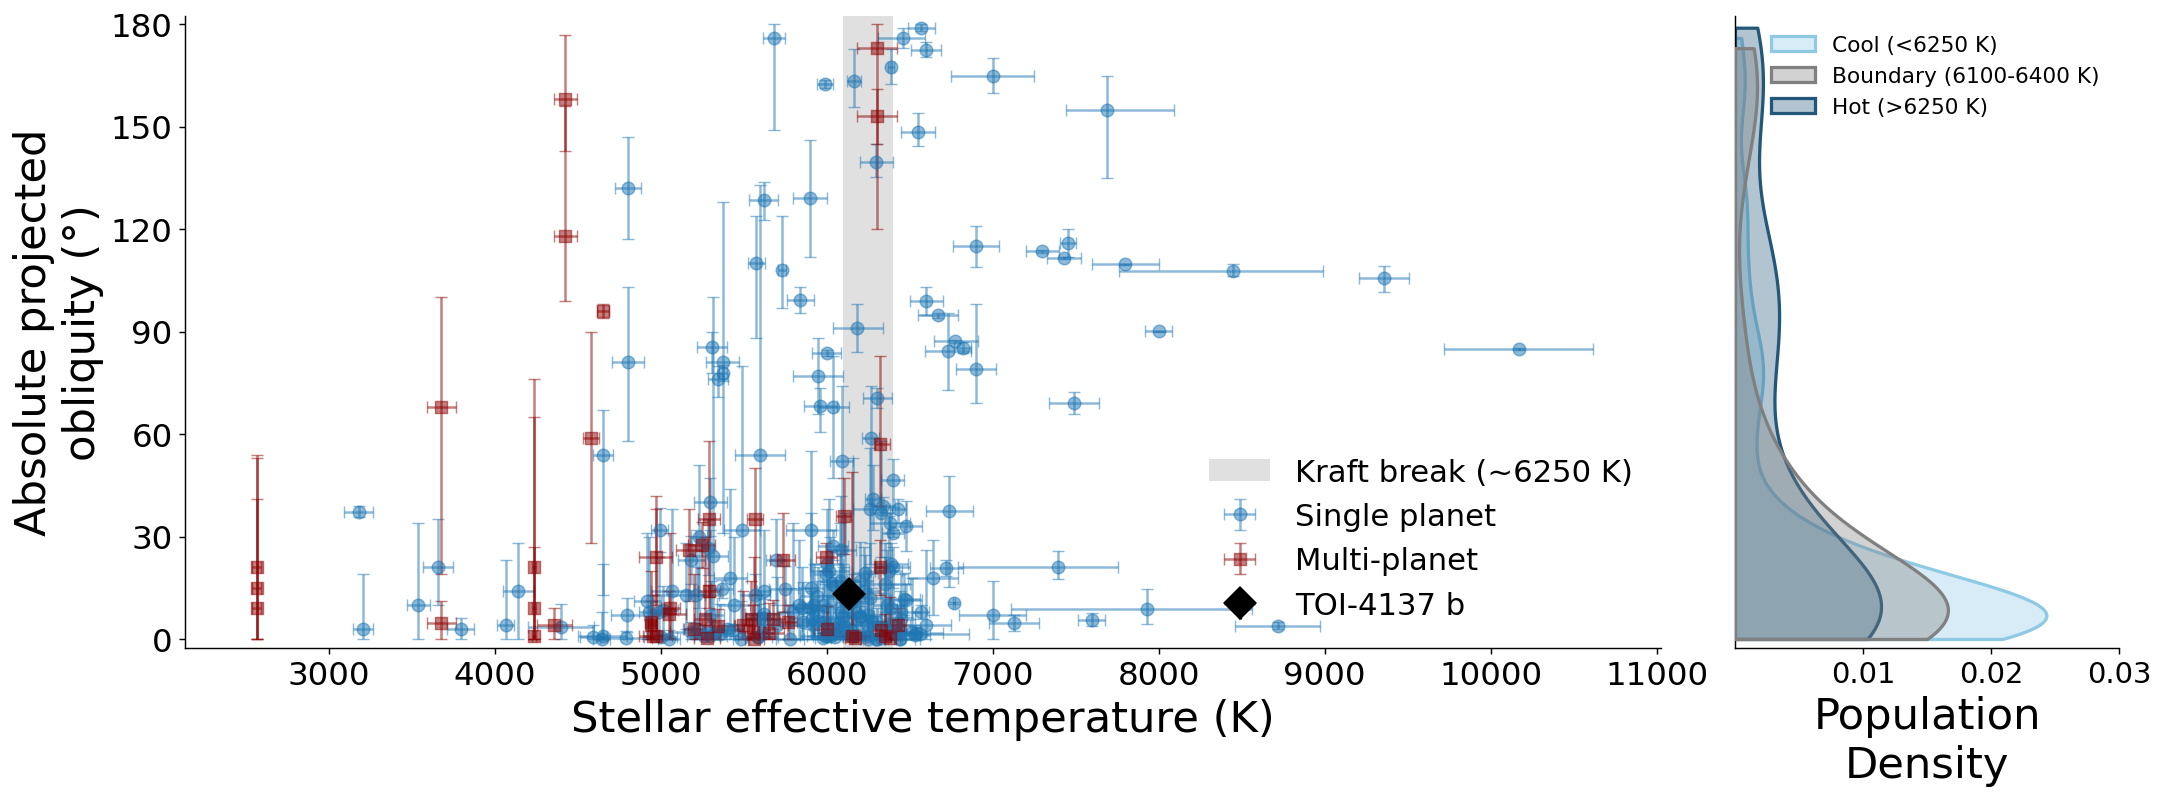

In [6]:
import seaborn as sns


def fold_obliquity(angle):
    angle = np.asarray(angle, dtype=float)
    return np.abs((angle + 180.0) % 360.0 - 180.0)


def fold_obliquity_interval(value, errdn, errup):
    center = float(fold_obliquity([value])[0])
    errdn, errup = abs(float(errdn)), abs(float(errup))
    if not np.isfinite(errdn) or not np.isfinite(errup):
        return center, errdn, errup

    interval_low, interval_high = value - errdn, value + errup
    first_critical = int(np.ceil(interval_low / 180.0))
    last_critical = int(np.floor(interval_high / 180.0))
    critical_angles = 180.0 * np.arange(first_critical, last_critical + 1)
    transformed = fold_obliquity(
        np.concatenate(([interval_low, interval_high], critical_angles))
    )
    return center, center - transformed.min(), transformed.max() - center


teff_df = final_merged_df.loc[
    final_merged_df["lambda"].notna() & final_merged_df["plot_teff"].notna()
].copy()
folded_values = [
    fold_obliquity_interval(value, errdn, errup)
    for value, errdn, errup in teff_df[
        ["lambda", "lambda_errdn", "lambda_errup"]
    ].itertuples(index=False, name=None)
]
teff_df[["lambda", "lambda_errdn", "lambda_errup"]] = np.asarray(folded_values)
single_teff_df, multi_teff_df = single_multi_split(teff_df)

fig, (ax, ax_density) = plt.subplots(
    1, 2, figsize=(17, 6), sharey=True,
    gridspec_kw={"width_ratios": [4.8, 1.25], "wspace": 0.08},
)
plot_population_group(
    ax,
    single_teff_df,
    x_col="plot_teff",
    xerr_lower_col="plot_tefferr2",
    xerr_upper_col="plot_tefferr1",
    marker="o",
    color=STYLE["single_color"],
    label="Single planet",
)
plot_population_group(
    ax,
    multi_teff_df,
    x_col="plot_teff",
    xerr_lower_col="plot_tefferr2",
    xerr_upper_col="plot_tefferr1",
    marker="s",
    color=STYLE["multi_color"],
    label="Multi-planet",
)
kraft_half_width = STYLE["kraft_break_half_width"]
kraft_low = STYLE["kraft_break_teff"] - kraft_half_width
kraft_high = STYLE["kraft_break_teff"] + kraft_half_width
ax.axvspan(
    kraft_low,
    kraft_high,
    color=STYLE["kraft_break_color"],
    alpha=STYLE["kraft_break_alpha"],
    linewidth=0,
    label=fr"Kraft break (~{STYLE['kraft_break_teff']:.0f} K)",
    zorder=1,
)
plot_toi_4137b(
    ax,
    x=toi_4137b["plot_teff"],
    xerr_lower=toi_4137b["plot_tefferr2"],
    xerr_upper=toi_4137b["plot_tefferr1"],
)

if STYLE["teff_xlim"] is not None:
    ax.set_xlim(*STYLE["teff_xlim"])
ax.set_xlabel(r"Stellar effective temperature (K)")
ax.set_ylabel("Absolute projected\nobliquity (°)")
ax.set_ylim(0, 180)
ax.set_yticks(np.arange(0, 181, 30))
ax.tick_params(axis="both", which="major", labelsize=STYLE["tick_labelsize"])
if STYLE["show_grid"]:
    ax.grid(True, alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])
else:
    ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

main_handles, main_labels = ax.get_legend_handles_labels()
main_legend = dict(zip(main_labels, main_handles))
main_order = [
    fr"Kraft break (~{STYLE['kraft_break_teff']:.0f} K)",
    "Single planet",
    "Multi-planet",
    "TOI-4137 b",
]
ax.legend(
    [main_legend[label] for label in main_order],
    main_order,
    loc="lower right",
    frameon=False,
    fontsize=STYLE["legend_fontsize"],
)

density_df = teff_df[["System", "plot_teff", "lambda"]].copy()
density_df["is_toi"] = False
density_df = pd.concat(
    [
        density_df,
        pd.DataFrame(
            {
                "System": [TOI_NAME],
                "plot_teff": [toi_4137b["plot_teff"]],
                "lambda": [float(fold_obliquity([toi_4137b["lambda"]])[0])],
                "is_toi": [True],
            }
        ),
    ],
    ignore_index=True,
)

cool_values = density_df.loc[density_df["plot_teff"] < kraft_low, "lambda"]
hot_values = density_df.loc[density_df["plot_teff"] > kraft_high, "lambda"]
boundary_values = density_df.loc[
    density_df["plot_teff"].between(kraft_low, kraft_high, inclusive="both")
    | density_df["is_toi"],
    "lambda",
]

density_groups = [
    (cool_values, "#8ecae6", f"Cool (<{kraft_low:.0f} K)", 1),
    (boundary_values, "0.50", f"Boundary ({kraft_low:.0f}-{kraft_high:.0f} K)", 3),
    (hot_values, "#22577a", f"Hot (>{kraft_high:.0f} K)", 2),
]
for values, color, label, zorder in density_groups:
    sns.kdeplot(
        y=values,
        ax=ax_density,
        color=color,
        fill=True,
        alpha=0.35,
        linewidth=1.8,
        bw_adjust=0.8,
        clip=(0, 180),
        cut=0,
        gridsize=400,
        label=label,
        warn_singular=False,
        zorder=zorder,
    )

ax_density.set_xlabel("Population\nDensity")
ax_density.set_ylabel("")
ax_density.set_ylim(-2.5, 182.5)
ax_density.set_xlim(left=0)
density_ticks = ax_density.get_xticks()
ax_density.set_xticks(density_ticks[density_ticks > 0])
ax_density.tick_params(
    axis="x", which="major", labelsize=STYLE["tick_labelsize"] - 2
)
ax_density.tick_params(axis="y", which="both", left=False, labelleft=False)
ax_density.grid(False)
ax_density.spines["top"].set_visible(False)
ax_density.spines["right"].set_visible(False)
ax_density.legend(loc="upper right", frameon=False, fontsize=12)

fig.subplots_adjust(left=0.11, right=0.985, bottom=0.16, top=0.97, wspace=0.08)
output_figure = RUN_DIR / "plots" / "population_plot.pdf"
output_figure.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_figure, bbox_inches="tight")
print(f"Saved figure to: {output_figure}")
plt.show()


## Quick-Look X-Axis Tests

These cells reuse the same merged obliquity population and TOI-4137 b highlight, then test several possible x-axis choices. They are meant for exploration, so the helper below keeps the styling consistent while making compact multi-panel plots.


In [7]:
RSUN_IN_AU = 0.00465047

EXTRA_NUMERIC_COLUMNS = [
    "sy_pnum",
    "st_mass",
    "st_masserr1",
    "st_masserr2",
    "st_met",
    "st_meterr1",
    "st_meterr2",
    "st_rad",
    "st_raderr1",
    "st_raderr2",
    "pl_orbper",
    "pl_orbpererr1",
    "pl_orbpererr2",
    "pl_orbsmax",
    "pl_orbsmaxerr1",
    "pl_orbsmaxerr2",
    "pl_bmassj",
    "pl_bmassjerr1",
    "pl_bmassjerr2",
    "pl_bmasse",
    "pl_bmasseerr1",
    "pl_bmasseerr2",
    "pl_radj",
    "pl_radjerr1",
    "pl_radjerr2",
    "pl_rade",
    "pl_radeerr1",
    "pl_radeerr2",
    "pl_eqt",
    "pl_eqterr1",
    "pl_eqterr2",
]

final_merged_df = numericize(final_merged_df, EXTRA_NUMERIC_COLUMNS)
for column in EXTRA_NUMERIC_COLUMNS:
    toi_4137b[column] = pd.to_numeric(toi_archive.get(column, np.nan), errors="coerce")


def add_a_over_rstar(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    sma = pd.to_numeric(df["pl_orbsmax"], errors="coerce")
    rad = pd.to_numeric(df["st_rad"], errors="coerce")
    df["a_over_rstar"] = sma / (rad * RSUN_IN_AU)

    sma_err_up = pd.to_numeric(df["pl_orbsmaxerr1"], errors="coerce").abs()
    sma_err_dn = pd.to_numeric(df["pl_orbsmaxerr2"], errors="coerce").abs()
    rad_err_up = pd.to_numeric(df["st_raderr1"], errors="coerce").abs()
    rad_err_dn = pd.to_numeric(df["st_raderr2"], errors="coerce").abs()

    with np.errstate(divide="ignore", invalid="ignore"):
        upper_rel = np.sqrt((sma_err_up / sma) ** 2 + (rad_err_dn / rad) ** 2)
        lower_rel = np.sqrt((sma_err_dn / sma) ** 2 + (rad_err_up / rad) ** 2)

    df["a_over_rstarerr1"] = df["a_over_rstar"] * upper_rel
    df["a_over_rstarerr2"] = -df["a_over_rstar"] * lower_rel
    return df


final_merged_df = add_a_over_rstar(final_merged_df)
toi_a_over_rstar = add_a_over_rstar(pd.DataFrame([toi_4137b])).iloc[0]
for column in ["a_over_rstar", "a_over_rstarerr1", "a_over_rstarerr2"]:
    toi_4137b[column] = toi_a_over_rstar[column]


In [8]:
def clean_asym_err(lower, upper):
    err = asym_err(lower, upper)
    err[~np.isfinite(err)] = 0.0
    return err


def optional_asym_err(df, lower_col=None, upper_col=None):
    if lower_col is None or upper_col is None:
        return None
    if lower_col not in df.columns or upper_col not in df.columns:
        return None
    return clean_asym_err(df[lower_col], df[upper_col])


def finite_float(value):
    value = pd.to_numeric(pd.Series([value]), errors="coerce").iloc[0]
    return float(value) if pd.notna(value) and np.isfinite(value) else np.nan


def plot_quick_group(ax, df, x_values, xerr, marker, color, label):
    if df.empty:
        return
    ax.errorbar(
        x_values,
        df["lambda"],
        xerr=xerr,
        yerr=clean_asym_err(df["lambda_errdn"], df["lambda_errup"]),
        fmt=marker,
        linestyle="None",
        markersize=max(STYLE["marker_size"] - 1, 3),
        markeredgewidth=0.7,
        color=color,
        ecolor=color,
        elinewidth=STYLE["line_width"],
        capsize=STYLE["cap_size"],
        alpha=STYLE["population_alpha"],
        label=label,
        zorder=2,
    )


def format_quick_axis(ax, xlabel, xscale=None, xlim=None):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$\lambda$ (deg)")
    ax.set_ylim(*STYLE["obliquity_ylim"])
    if xscale is not None:
        ax.set_xscale(xscale)
    if xlim is not None:
        ax.set_xlim(*xlim)
    ax.tick_params(axis="both", which="major", labelsize=STYLE["tick_labelsize"] - 2)
    ax.grid(STYLE["show_grid"], alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def plot_quick_xaxis(ax, spec):
    x_col = spec["x_col"]
    df = final_merged_df.loc[
        final_merged_df["lambda"].notna() & final_merged_df[x_col].notna()
    ].copy()
    if spec.get("xscale") == "log":
        df = df.loc[df[x_col] > 0].copy()

    single_df, multi_df = single_multi_split(df)
    for group_df, marker, color, label in [
        (single_df, "o", STYLE["single_color"], "Single planet"),
        (multi_df, "s", STYLE["multi_color"], "Multi-planet"),
    ]:
        x_values = pd.to_numeric(group_df[x_col], errors="coerce").to_numpy(dtype=float)
        jitter = spec.get("jitter", 0)
        if jitter:
            offsets = ((np.arange(len(group_df)) % 9) - 4) * (jitter / 4)
            x_values = x_values + offsets
        plot_quick_group(
            ax,
            group_df,
            x_values,
            optional_asym_err(group_df, spec.get("xerr_lower"), spec.get("xerr_upper")),
            marker=marker,
            color=color,
            label=label,
        )

    toi_x = finite_float(toi_4137b.get(x_col, np.nan))
    if np.isfinite(toi_x) and not (spec.get("xscale") == "log" and toi_x <= 0):
        plot_toi_4137b(
            ax,
            x=toi_x,
            xerr_lower=finite_float(toi_4137b.get(spec.get("xerr_lower"), 0.0)) if spec.get("xerr_lower") else 0.0,
            xerr_upper=finite_float(toi_4137b.get(spec.get("xerr_upper"), 0.0)) if spec.get("xerr_upper") else 0.0,
        )

    format_quick_axis(ax, spec["xlabel"], xscale=spec.get("xscale"), xlim=spec.get("xlim"))
    ax.set_title(spec.get("title", spec["xlabel"]), fontsize=STYLE["axes_titlesize"] - 4)


def make_quick_grid(specs, ncols=2, title=None):
    nrows = int(np.ceil(len(specs) / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(STYLE["figure_size"][0], 4.5 * nrows),
        squeeze=False,
    )
    flat_axes = axes.ravel()
    for ax, spec in zip(flat_axes, specs):
        plot_quick_xaxis(ax, spec)
    for ax in flat_axes[len(specs):]:
        ax.axis("off")

    handles, labels = flat_axes[0].get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    fig.legend(
        list(unique.values()),
        list(unique.keys()),
        frameon=False,
        loc="upper center",
        ncol=min(3, len(unique)),
        fontsize=STYLE["legend_fontsize"],
    )
    if title is not None:
        fig.suptitle(title, fontsize=STYLE["axes_titlesize"], y=0.995)
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


/tmp/ipykernel_625436/237014832.py:51: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(STYLE["show_grid"], alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])


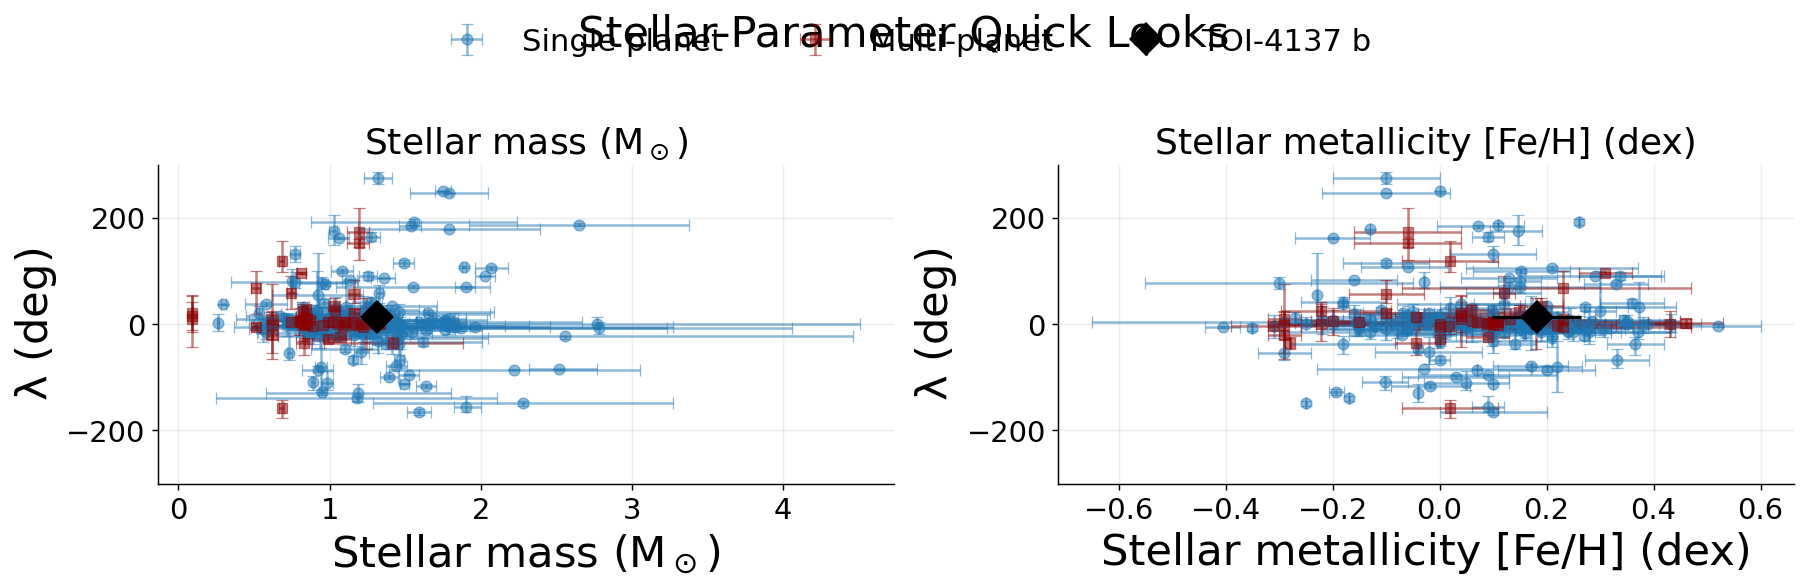

In [9]:
stellar_xaxis_tests = [
    {
        "x_col": "st_mass",
        "xlabel": r"Stellar mass ($M_\odot$)",
        "xerr_lower": "st_masserr2",
        "xerr_upper": "st_masserr1",
    },
    {
        "x_col": "st_met",
        "xlabel": r"Stellar metallicity [Fe/H] (dex)",
        "xerr_lower": "st_meterr2",
        "xerr_upper": "st_meterr1",
    },
]

make_quick_grid(stellar_xaxis_tests, ncols=2, title="Stellar-Parameter Quick Looks")


/tmp/ipykernel_625436/237014832.py:51: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(STYLE["show_grid"], alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])


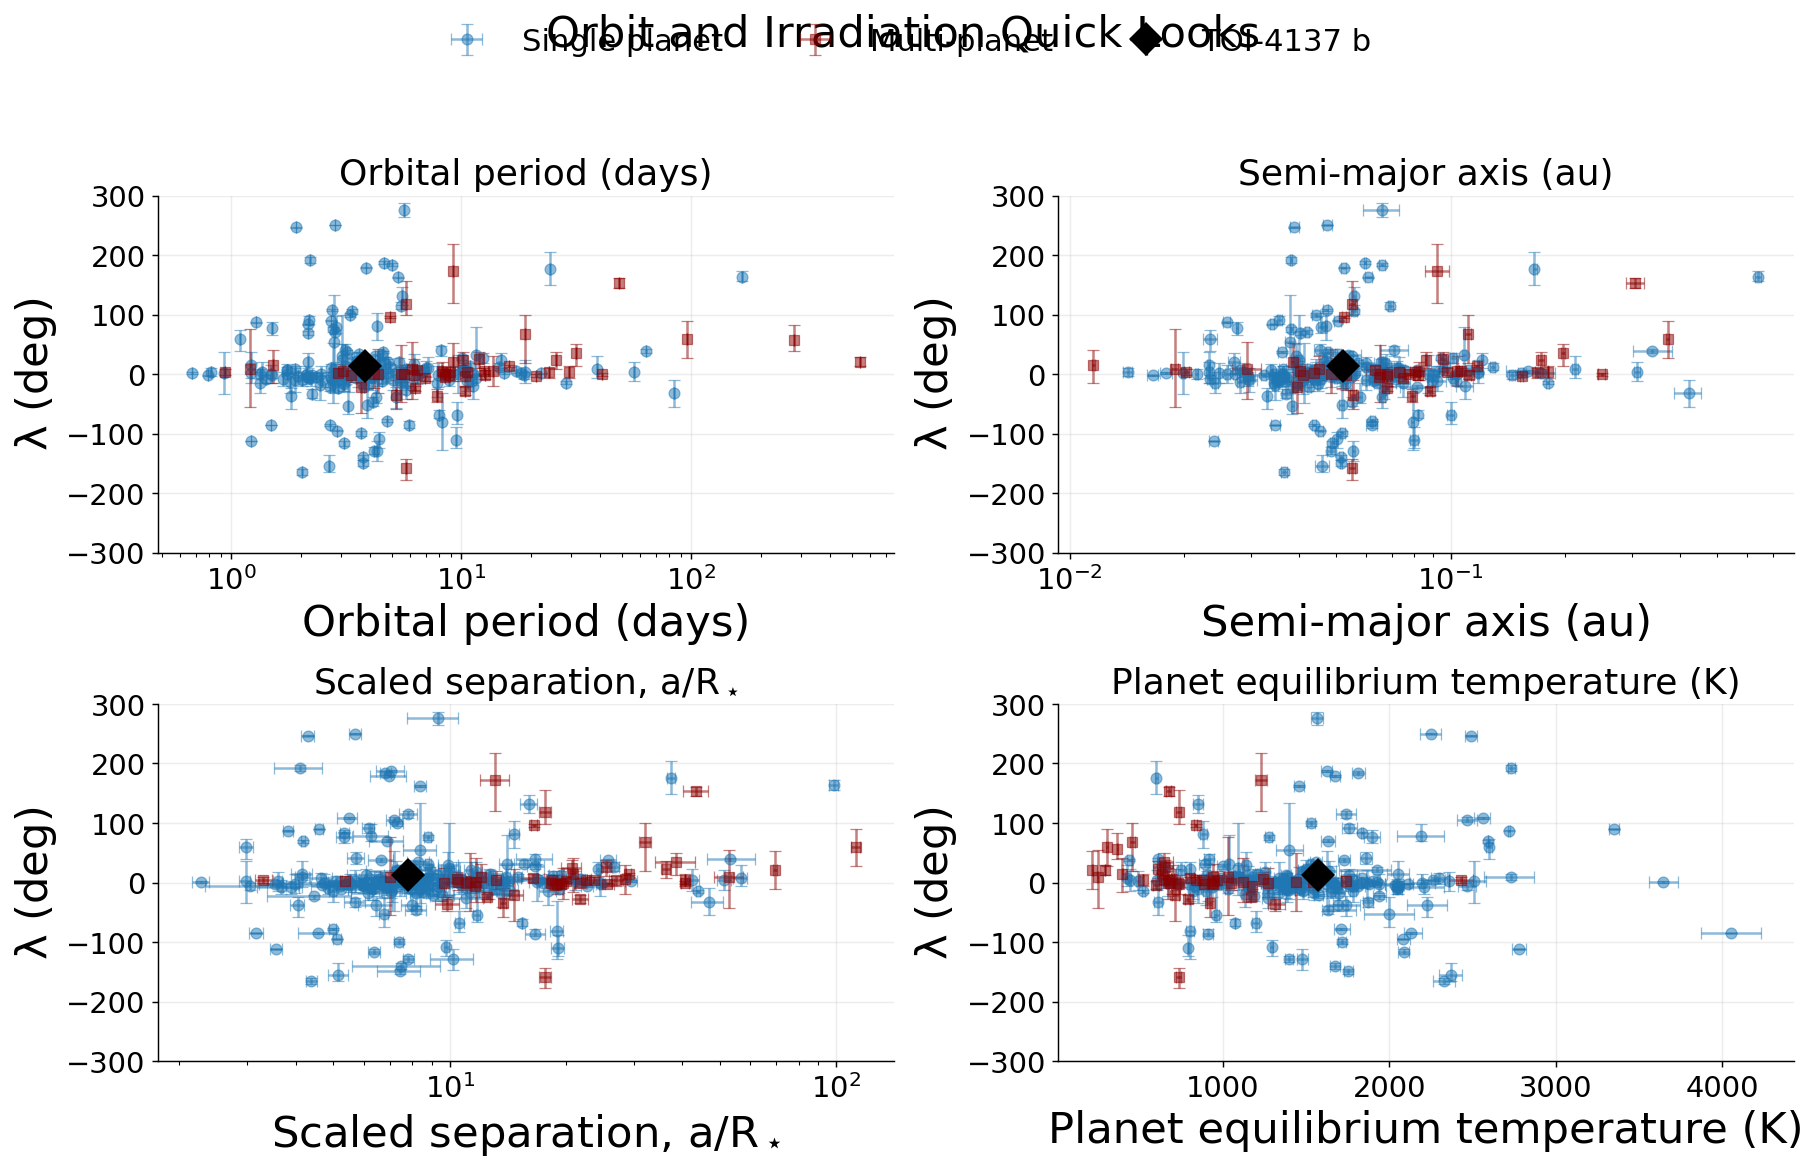

In [10]:
orbital_xaxis_tests = [
    {
        "x_col": "pl_orbper",
        "xlabel": "Orbital period (days)",
        "xerr_lower": "pl_orbpererr2",
        "xerr_upper": "pl_orbpererr1",
        "xscale": "log",
    },
    {
        "x_col": "pl_orbsmax",
        "xlabel": "Semi-major axis (au)",
        "xerr_lower": "pl_orbsmaxerr2",
        "xerr_upper": "pl_orbsmaxerr1",
        "xscale": "log",
    },
    {
        "x_col": "a_over_rstar",
        "xlabel": r"Scaled separation, $a/R_\star$",
        "xerr_lower": "a_over_rstarerr2",
        "xerr_upper": "a_over_rstarerr1",
        "xscale": "log",
    },
    {
        "x_col": "pl_eqt",
        "xlabel": "Planet equilibrium temperature (K)",
        "xerr_lower": "pl_eqterr2",
        "xerr_upper": "pl_eqterr1",
    },
]

make_quick_grid(orbital_xaxis_tests, ncols=2, title="Orbit and Irradiation Quick Looks")


/tmp/ipykernel_625436/237014832.py:51: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(STYLE["show_grid"], alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])


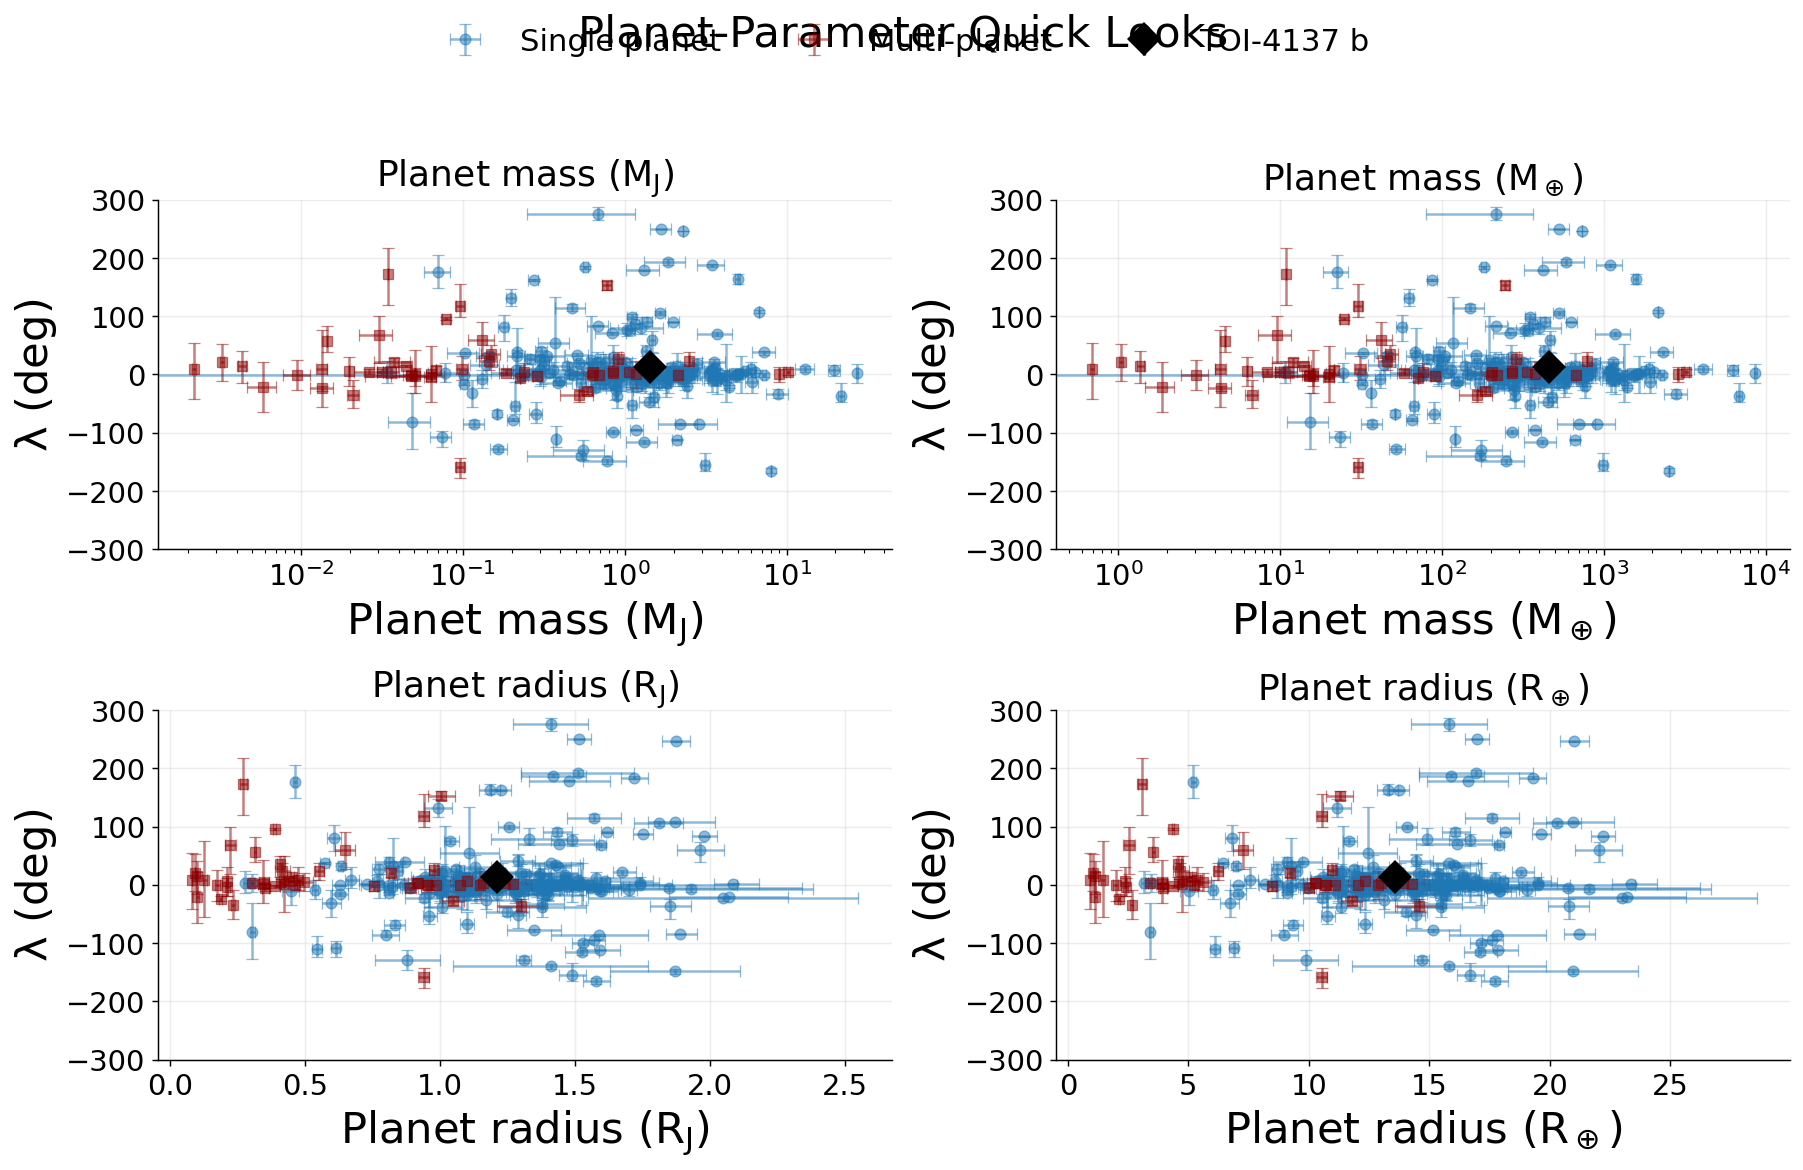

In [11]:
planet_xaxis_tests = [
    {
        "x_col": "pl_bmassj",
        "xlabel": r"Planet mass ($M_{\rm J}$)",
        "xerr_lower": "pl_bmassjerr2",
        "xerr_upper": "pl_bmassjerr1",
        "xscale": "log",
    },
    {
        "x_col": "pl_bmasse",
        "xlabel": r"Planet mass ($M_\oplus$)",
        "xerr_lower": "pl_bmasseerr2",
        "xerr_upper": "pl_bmasseerr1",
        "xscale": "log",
    },
    {
        "x_col": "pl_radj",
        "xlabel": r"Planet radius ($R_{\rm J}$)",
        "xerr_lower": "pl_radjerr2",
        "xerr_upper": "pl_radjerr1",
    },
    {
        "x_col": "pl_rade",
        "xlabel": r"Planet radius ($R_\oplus$)",
        "xerr_lower": "pl_radeerr2",
        "xerr_upper": "pl_radeerr1",
    },
]

make_quick_grid(planet_xaxis_tests, ncols=2, title="Planet-Parameter Quick Looks")


/tmp/ipykernel_625436/237014832.py:51: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(STYLE["show_grid"], alpha=STYLE["grid_alpha"], linewidth=STYLE["grid_line_width"])


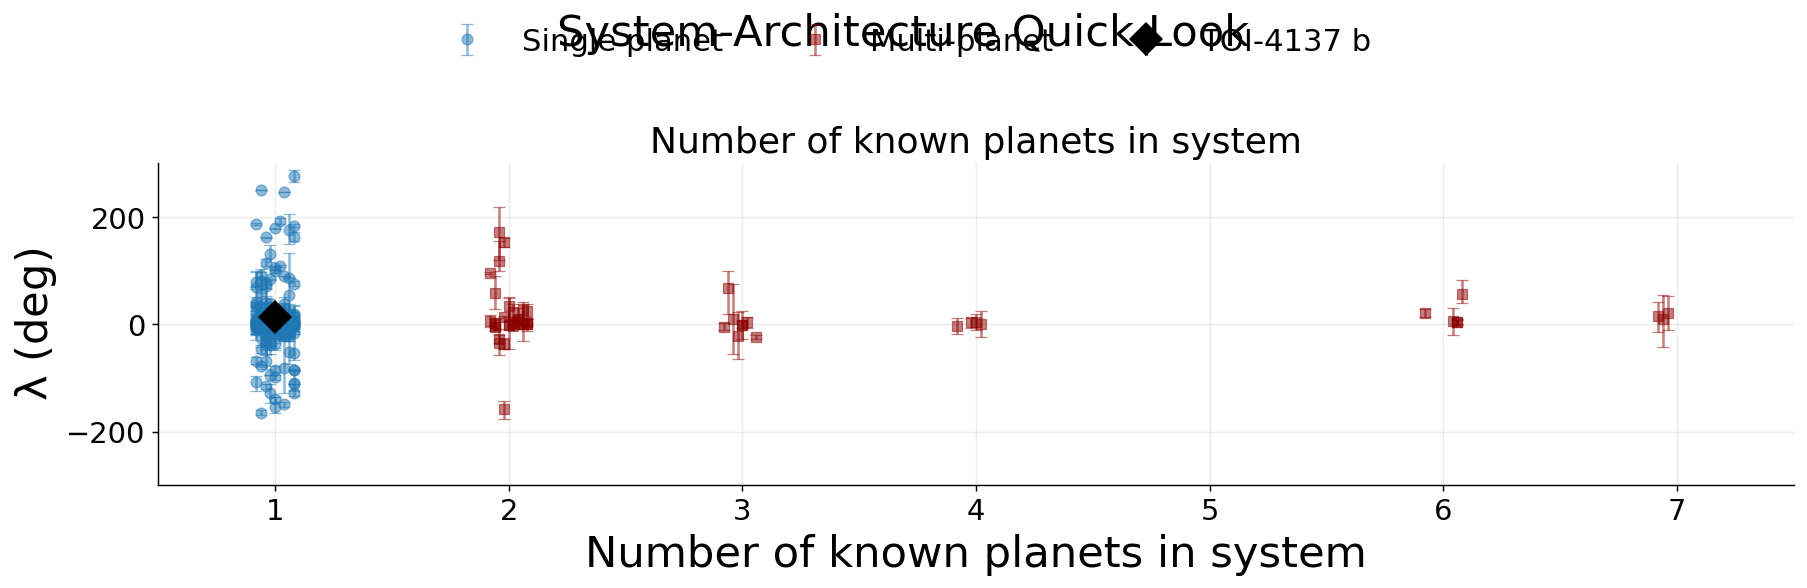

In [12]:
multiplicity_xaxis_tests = [
    {
        "x_col": "sy_pnum",
        "xlabel": "Number of known planets in system",
        "jitter": 0.08,
        "xlim": (0.5, max(7.5, final_merged_df["sy_pnum"].max() + 0.5)),
    },
]

make_quick_grid(multiplicity_xaxis_tests, ncols=1, title="System-Architecture Quick Look")
